## Problema - Parcial Prioridad mst





#### Andrés Felipe Rubio Arango

## 1) Descripción del problema **[1 pts]**
Una empresa necesita administrar tareas técnicas según su nivel de prioridad, y al mismo tiempo conectar seis dispositivos en un plano utilizando la menor longitud total de cable posible. Para resolverlo, se implementará un Max-Heap y se modelará la red de dispositivos como un grafo para hallar su Árbol de Expansión Mínima (MST) mediante el algoritmo de Kruskal.

## 2) Requerimientos **[2 pts]**

### Requerimientos funcionales
RF1: Construcción del Max-Heap: Construir un Max-Heap a partir de las seis tareas iniciales (T01 a T06) usando MAX-HEAPIFY y BUILD-MAX-HEAP, mostrando el arreglo inicial, el heap resultante y la estructura del árbol.

RF2: Procesamiento e inserción de tareas: Implementar EXTRACT-MAX para procesar las dos tareas de mayor prioridad e insertar la tarea T07 conservando la propiedad de Max-Heap.

RF3: Posiciones y cálculo de distancias: Graficar los seis dispositivos según sus coordenadas y calcular automáticamente la distancia euclidiana entre cada pareja de dispositivos como peso de cada arista.

RF4: Cálculo del MST con Kruskal: Ordenar las aristas por peso, seleccionar conexiones de menor costo evitando ciclos hasta conectar los 6 dispositivos y reportar cada conexión y la longitud total de cable.

RF5: Visualización del MST: Generar una gráfica final con los seis dispositivos, únicamente las 5 aristas del MST, el peso de cada conexión y la longitud total de cable.

### Requerimientos no funcionales
RNF1: Restricción de librerías: No utilizar funciones de librerías que calculen directamente el MST.

RNF2: Legibilidad y precisión: Mostrar los valores de distancia y longitud total con dos decimales (XX.XX) y mantener el código modular y reproducible.



## 3) Historias de usuario **[2 pts]**
### HU1: Priorización inicial de tareas técnicas
Historia: Como coordinador de operaciones técnicas, quiero construir un Max-Heap con las tareas iniciales y ver su árbol para identificar rápidamente la tarea más urgente.
 
#### Criterios de aceptación:
Se muestra el arreglo inicial y el Max-Heap resultante tras ejecutar BUILD-MAX-HEAP.
Todo nodo padre tiene prioridad mayor o igual que sus hijos y se muestra la representación del árbol.

### HU2: Atención de tareas críticas e ingreso de emergencia
Historia: Como operador del sistema, quiero extraer las dos tareas de mayor prioridad y registrar una nueva tarea crítica (T07) sin romper el orden de prioridad para atender emergencias a tiempo.
 
#### Criterios de aceptación:
Se extraen dos veces el máximo con EXTRACT-MAX, mostrando en cada paso la tarea procesada y el heap actualizado.
Al insertar T07 (prioridad 12), el elemento sube según la propiedad de Max-Heap y el heap sigue válido.

### HU3: Mapeo de dispositivos y pesos de conexión
Historia: Como ingeniero de infraestructura, quiero graficar la ubicación de los seis dispositivos y calcular todas las distancias entre pares para conocer el costo de cada posible enlace.
 
#### Criterios de aceptación:
Se genera la gráfica con los 6 dispositivos (A–F) en sus coordenadas (X, Y).
Se calcula automáticamente \sqrt{(x_2 - x_1)^2 + (y_2 - y_1)^2} para cada par de nodos.

### HU4: Minimización de cableado con Kruskal y visualización
Historia: Como diseñador de red, quiero obtener el Árbol de Expansión Mínima de forma manual y verlo graficado para minimizar la cantidad total de cable utilizada.
 
#### Criterios de aceptación:
El algoritmo selecciona exactamente 5 aristas sin formar ciclos y muestra la longitud total de cable.
La gráfica final exhibe los 6 dispositivos, solo las aristas del MST, el peso de cada arista y la longitud total.


## 4) Diagramas de flujo **[5 pts]**
![Producto Hash Table Management Flow-2026-11-24-125121.png](<attachment:Producto Hash Table Management Flow-2026-11-24-125121.png>)

### 5) Análisis de complejidad **[15 pts]**
#### Justificación
Max-Heap (BUILD-MAX-HEAP, EXTRACT-MAX e inserción): Para n tareas, MAX-HEAPIFY desciende por la altura del árbol binario completo, que es O(\log n). BUILD-MAX-HEAP llama a MAX-HEAPIFY desde \lfloor n/2 \rfloor - 1 hasta 0, lo que tiene un costo total acotado en O(n) (y cota superior simple O(n \log n)). Tanto EXTRACT-MAX como insertar T07 realizan un intercambio y un recorrido a lo largo de una rama de altura a lo sumo \log_2 n, tomando O(\log n). 
 
Kruskal con Union-Find: Con V = 6 dispositivos y E = \frac{V(V-1)}{2} = 15 aristas (en general E = O(V^2) para grafo completo), ordenar las E aristas toma O(E \log E), y recorrer las aristas aplicando find y union (con compresión de caminos/unión) toma casi tiempo constante amortizado por operación. 
 
Función T[n]
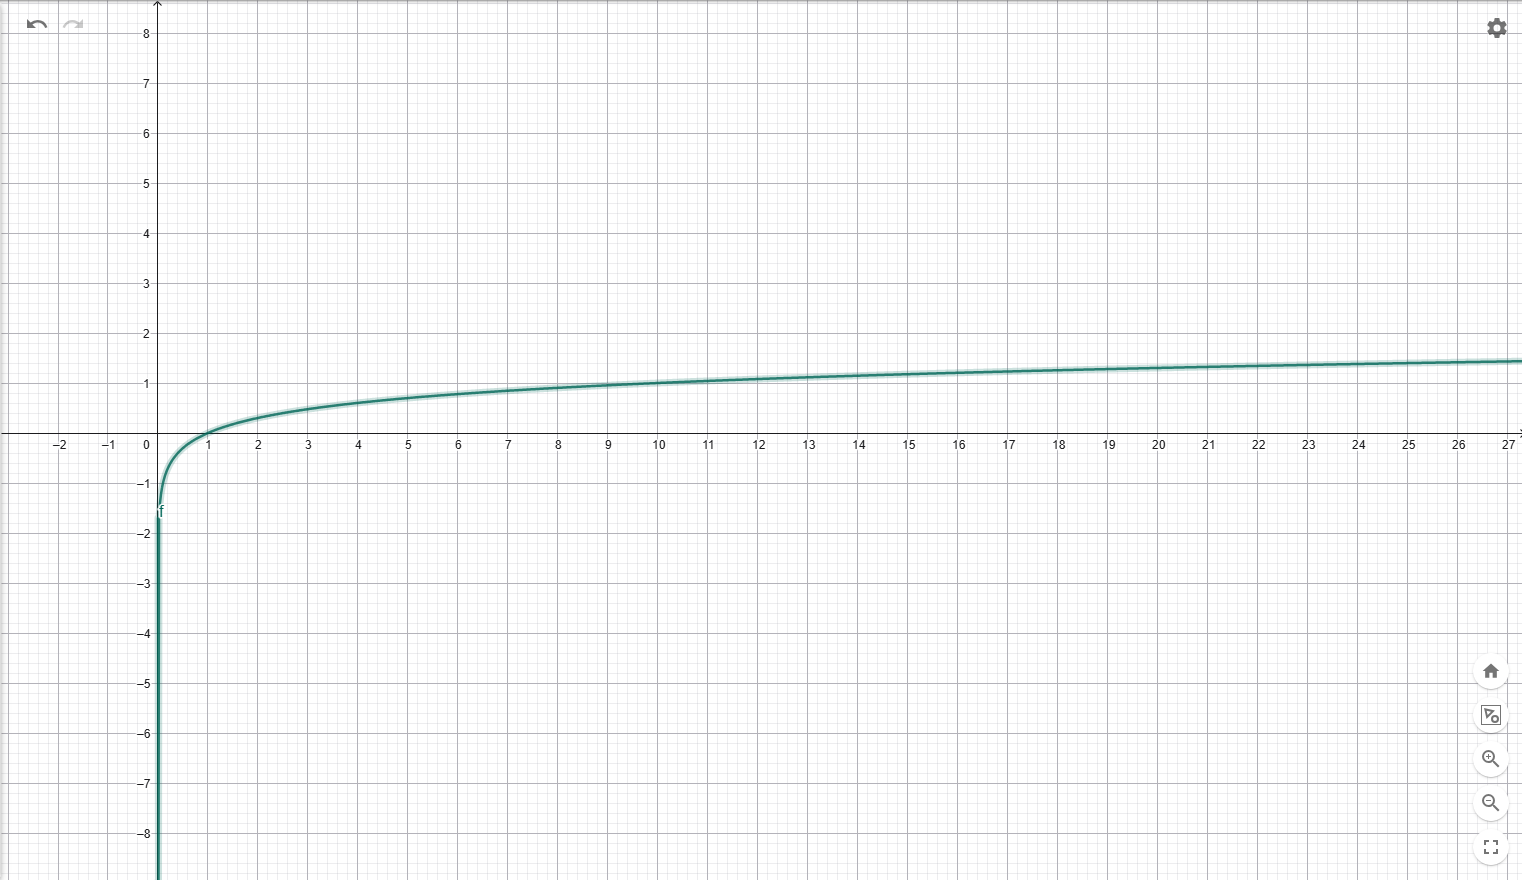
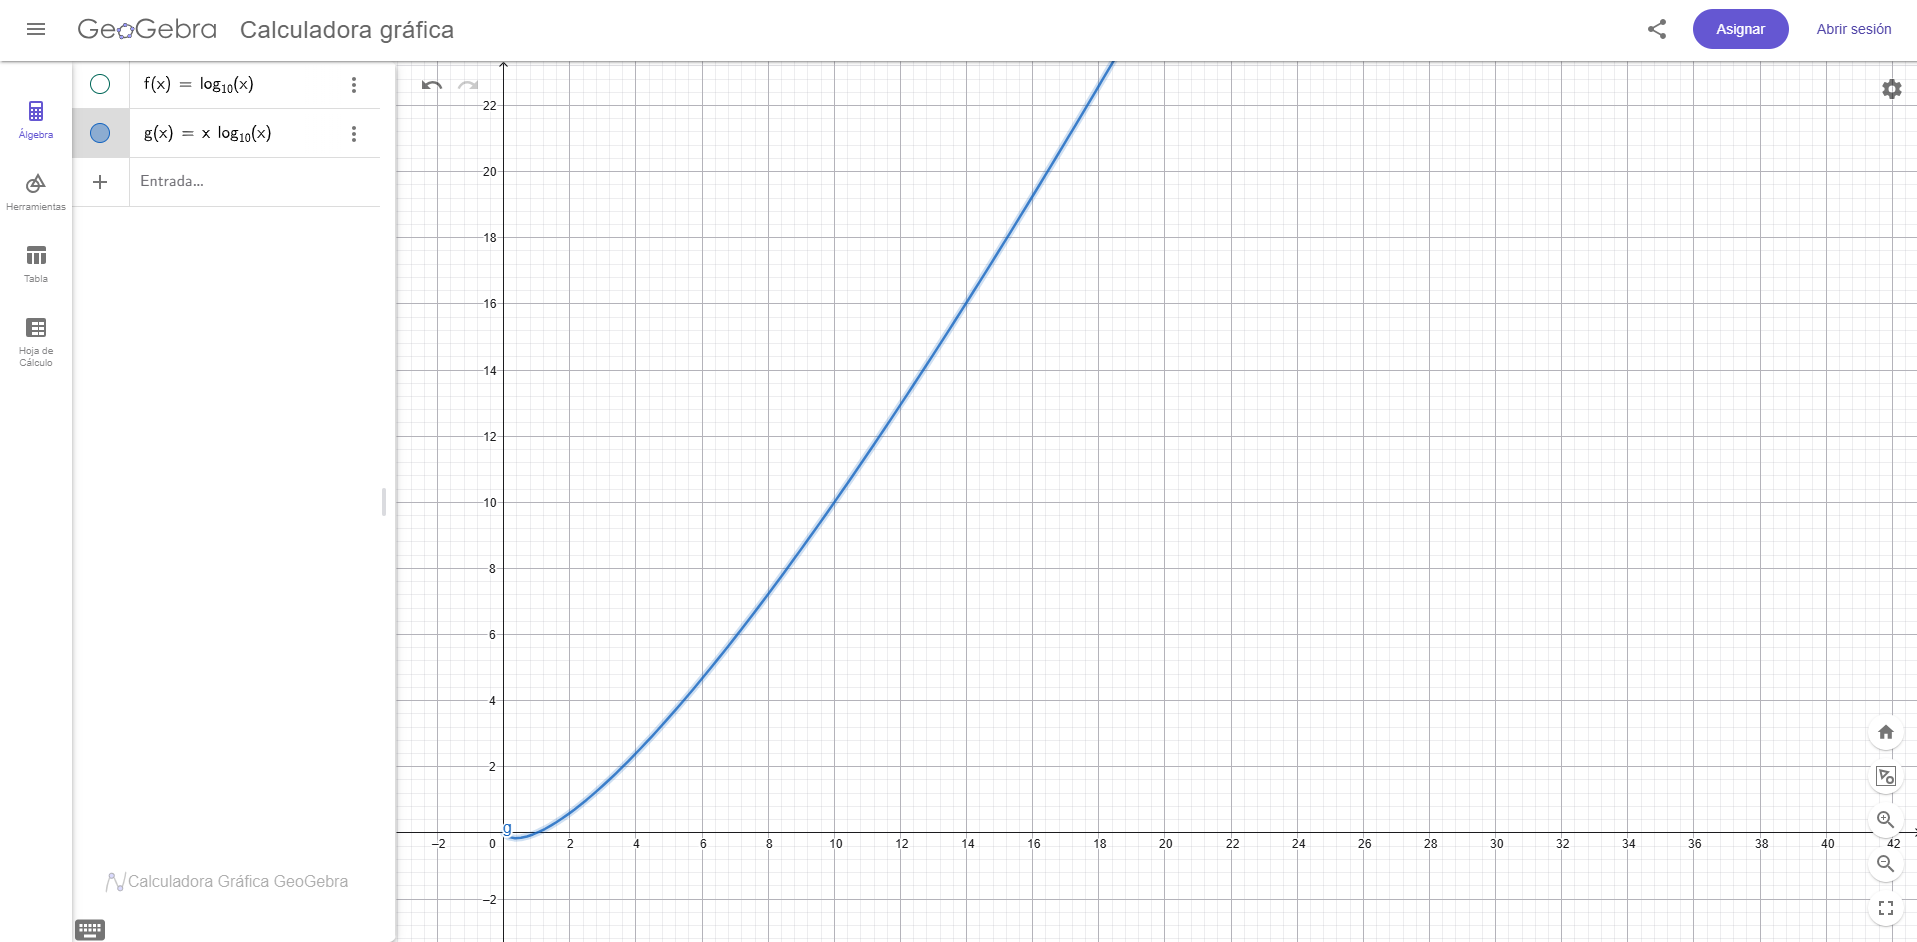
 
 

## 6) Código funcional **[15 pts]**

In [ ]:
# 1.Cola de prioridad
tareas_iniciales = [
    {"codigo": "T01", "nombre": "Configurar servidor", "prioridad": 6},
    {"codigo": "T02", "nombre": "Reparar sensor", "prioridad": 10},
    {"codigo": "T03", "nombre": "Actualizar software", "prioridad": 4},
    {"codigo": "T04", "nombre": "Revisar cámara", "prioridad": 8},
    {"codigo": "T05", "nombre": "Generar respaldo", "prioridad": 3},
    {"codigo": "T06", "nombre": "Configurar alarma", "prioridad": 7},
]
def max_heapify(heap, n, i):
    mayor = i
    izq = 2 * i + 1
    der = 2 * i + 2
    if izq < n and heap[izq]["prioridad"] > heap[mayor]["prioridad"]:
        mayor = izq
    if der < n and heap[der]["prioridad"] > heap[mayor]["prioridad"]:
        mayor = der
    if mayor != i:
        heap[i], heap[mayor] = heap[mayor], heap[i]
        max_heapify(heap, n, mayor)
def build_max_heap(arreglo):
    heap = arreglo.copy()
    n = len(heap)
    for i in range(n // 2 - 1, -1, -1):
        max_heapify(heap, n, i)
    return heap
def mostrar_arreglo(titulo, heap):
    print(f"--- {titulo} ---")
    for t in heap:
        print(f"[{t['codigo']} | P:{t['prioridad']} - {t['nombre']}]")
    print()
def mostrar_arbol(heap):
    print("--- Árbol correspondiente al Max-Heap ---")
    n = len(heap)
    for i in range(n):
        padre = f"{heap[i]['codigo']}(P:{heap[i]['prioridad']})"
        izq_idx = 2 * i + 1
        der_idx = 2 * i + 2
        izq = (
            f"{heap[izq_idx]['codigo']}(P:{heap[izq_idx]['prioridad']})"
            if izq_idx < n
            else "None"
        )
        der = (
            f"{heap[der_idx]['codigo']}(P:{heap[der_idx]['prioridad']})"
            if der_idx < n
            else "None"
        )
        print(f"Nodo {padre} -> Izq: {izq} | Der: {der}")
    print()
# Ejecución Punto 1
mostrar_arreglo("Arreglo Inicial", tareas_iniciales)
max_heap = build_max_heap(tareas_iniciales)
mostrar_arreglo("Max-Heap Resultante", max_heap)
mostrar_arbol(max_heap)
# 2.Procesar tareas
def extract_max(heap):
    if len(heap) == 0:
        return None
    maximo = heap[0]
    heap[0] = heap[-1]
    heap.pop()
    if len(heap) > 0:
        max_heapify(heap, len(heap), 0)
    return maximo
def heap_insert(heap, nueva_tarea):
    heap.append(nueva_tarea)
    i = len(heap) - 1
    padre = (i - 1) // 2
 
    # Flotar el elemento hacia arriba (Increase-Key)
    while i > 0 and heap[padre]["prioridad"] < heap[i]["prioridad"]:
        heap[i], heap[padre] = heap[padre], heap[i]
        i = padre
        padre = (i - 1) // 2
# 1. Extraer las dos tareas de mayor prioridad
for paso in range(1, 3):
    procesada = extract_max(max_heap)
    print(
        f"Extracción {paso} -> Procesada: {procesada['codigo']} -"
        f" {procesada['nombre']} (Prioridad: {procesada['prioridad']})"
    )
    mostrar_arreglo(f"Heap después de Extracción {paso}", max_heap)
# 2. Insertar tarea T07
tarea_emergencia = {
    "codigo": "T07",
    "nombre": "Falla en sistema contra incendios",
    "prioridad": 12,
}
heap_insert(max_heap, tarea_emergencia)
mostrar_arreglo("Heap después de insertar T07 (Prioridad 12)", max_heap)
mostrar_arbol(max_heap)
# 3.Dispositivos a conectar
import math
import matplotlib.pyplot as plt
dispositivos = {
    "A": {"nombre": "Servidor", "x": 2, "y": 2},
    "B": {"nombre": "Cámara", "x": 7, "y": 3},
    "C": {"nombre": "Sensor", "x": 4, "y": 7},
    "D": {"nombre": "Alarma", "x": 10, "y": 8},
    "E": {"nombre": "Router", "x": 13, "y": 3},
    "F": {"nombre": "Panel", "x": 15, "y": 7},
}
# Calcular distancias entre todas las parejas
aristas = []
ids = list(dispositivos.keys())
for i in range(len(ids)):
    for j in range(i + 1, len(ids)):
        u, v = ids[i], ids[j]
        x1, y1 = dispositivos[u]["x"], dispositivos[u]["y"]
        x2, y2 = dispositivos[v]["x"], dispositivos[v]["y"]
        dist = math.sqrt((x2 - x1) ** 2 + (y2 - y1) ** 2)
        aristas.append({"u": u, "v": v, "peso": round(dist, 2)})
# Gráfica inicial de posiciones
plt.figure(figsize=(8, 5))
for id_disp, info in dispositivos.items():
    plt.scatter(info["x"], info["y"], s=150, color="steelblue", zorder=3)
    plt.text(
        info["x"] + 0.2,
        info["y"] + 0.2,
        f"{id_disp} ({info['nombre']})",
        fontsize=10,
        fontweight="bold",
    )
plt.title("Ubicación de dispositivos")
plt.xlabel("Coordenada X")
plt.ylabel("Coordenada Y")
plt.xlim(0, 18)
plt.ylim(0, 10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()
# 4.Árbol de expansión mínima
padre = {id_disp: id_disp for id_disp in dispositivos}
def find(nodo):
    if padre[nodo] != nodo:
        padre[nodo] = find(padre[nodo])
    return padre[nodo]
def union(nodo1, nodo2):
    raiz1 = find(nodo1)
    raiz2 = find(nodo2)
    if raiz1 != raiz2:
        padre[raiz2] = raiz1
        return True
    return False
# 1. Ordenar aristas por peso
aristas_ordenadas = sorted(aristas, key=lambda arista: arista["peso"])
# 2, 3 y 4. Seleccionar conexiones sin ciclos hasta tener n - 1 aristas (5 conexiones)
mst = []
longitud_total = 0.0
for arista in aristas_ordenadas:
    if union(arista["u"], arista["v"]):
        mst.append(arista)
        longitud_total += arista["peso"]
        if len(mst) == len(dispositivos) - 1:
            break
# Mostrar resultados en el formato solicitado
print("Conexiones seleccionadas (MST):")
for conexion in mst:
    print(f"{conexion['u']} - {conexion['v']}: {conexion['peso']:.2f}")
print(f"\nLongitud total de cable: {longitud_total:.2f}")
# 5.Visualización final
plt.figure(figsize=(9, 6))
# Dibujar únicamente las conexiones del MST y sus pesos
for conexion in mst:
    u, v, peso = conexion["u"], conexion["v"], conexion["peso"]
    x_vals = [dispositivos[u]["x"], dispositivos[v]["x"]]
    y_vals = [dispositivos[u]["y"], dispositivos[v]["y"]]
    plt.plot(x_vals, y_vals, color="forestgreen", linewidth=2.5, zorder=2)
    # Punto medio para colocar la etiqueta del peso
    mid_x = (x_vals[0] + x_vals[1]) / 2
    mid_y = (y_vals[0] + y_vals[1]) / 2
    plt.text(
        mid_x,
        mid_y,
        f"{peso:.2f}",
        color="darkred",
        fontsize=10,
        fontweight="bold",
        bbox=dict(
            facecolor="white", edgecolor="none", alpha=0.8, pad=1
        ),
    )
# Dibujar los seis dispositivos
for id_disp, info in dispositivos.items():
    plt.scatter(info["x"], info["y"], s=180, color="navy", zorder=3)
    plt.text(
        info["x"] + 0.25,
        info["y"] + 0.2,
        f"{id_disp} ({info['nombre']})",
        fontsize=10,
        fontweight="bold",
    )
plt.title(
    f"Árbol de Expansión Mínima (MST) — Longitud total de cable: {longitud_total:.2f}"
)
plt.xlabel("Coordenada X")
plt.ylabel("Coordenada Y")
plt.xlim(0, 18)
plt.ylim(0, 10)
plt.grid(True, linestyle="--", alpha=0.6)
plt.show()

## 7) Tests aplicados **[15 pts]**

In [ ]:
import math
def probar_todo():
    print("=== PRUEBAS DEL PARCIAL ===\n")
    # PRUEBA PUNTO 1: BUILD-MAX-HEAP y propiedad del Max-Heap
    assert len(tareas_iniciales) == 6, "Deben existir 6 tareas iniciales."
    heap_prueba = build_max_heap(tareas_iniciales)
    assert len(heap_prueba) == len(tareas_iniciales)
    # Verificar propiedad de Max-Heap: padre >= hijos
    n_h = len(heap_prueba)
    for i in range(n_h):
        izq = 2 * i + 1
        der = 2 * i + 2
        if izq < n_h:
            assert (
                heap_prueba[i]["prioridad"] >= heap_prueba[izq]["prioridad"]
            ), f"Fallo en hijo izquierdo de índice {i}"
        if der < n_h:
            assert (
                heap_prueba[i]["prioridad"] >= heap_prueba[der]["prioridad"]
            ), f"Fallo en hijo derecho de índice {i}"
    assert (
        heap_prueba[0]["codigo"] == "T02" and heap_prueba[0]["prioridad"] == 10
    ), "La raíz inicial debe ser T02 con prioridad 10."
    print("[OK] Punto 1: BUILD-MAX-HEAP y propiedad de Max-Heap verificados.")
    # PRUEBA PUNTO 2: Dos EXTRACT-MAX e inserción de T07 (P:12)
    ext_1 = extract_max(heap_prueba)
    assert (
        ext_1["codigo"] == "T02" and ext_1["prioridad"] == 10
    ), "Primera extracción debe ser T02 (10)."
    ext_2 = extract_max(heap_prueba)
    assert (
        ext_2["codigo"] == "T04" and ext_2["prioridad"] == 8
    ), "Segunda extracción debe ser T04 (8)."
    assert len(heap_prueba) == 4, "Deben quedar 4 tareas tras extraer 2."
    nueva_t07 = {
        "codigo": "T07",
        "nombre": "Falla en sistema contra incendios",
        "prioridad": 12,
    }
    heap_insert(heap_prueba, nueva_t07)
    assert len(heap_prueba) == 5, "Deben quedar 5 tareas tras insertar T07."
    assert (
        heap_prueba[0]["codigo"] == "T07" and heap_prueba[0]["prioridad"] == 12
    ), "Tras insertar T07 (12), debe quedar en la raíz."
    # Re-verificar propiedad de Max-Heap tras inserción
    for i in range(len(heap_prueba)):
        izq, der = 2 * i + 1, 2 * i + 2
        if izq < len(heap_prueba):
            assert (
                heap_prueba[i]["prioridad"] >= heap_prueba[izq]["prioridad"]
            )
        if der < len(heap_prueba):
            assert (
                heap_prueba[i]["prioridad"] >= heap_prueba[der]["prioridad"]
            )
    print(
        "[OK] Punto 2: EXTRACT-MAX (x2) e inserción de T07 (prioridad 12)"
        " verificados."
    )
    # PRUEBA PUNTO 3: Dispositivos y cálculo de distancias
    assert len(dispositivos) == 6, "Deben existir 6 dispositivos (A-F)."
    # En un grafo completo de 6 nodos hay 6*(6-1)/2 = 15 aristas
    assert len(aristas) == 15, f"Se esperaban 15 aristas, hay {len(aristas)}."
    # Comprobar distancia A(2,2) a B(7,3) -> sqrt(5^2 + 1^2) = sqrt(26) ≈ 5.10
    ab = next(
        (
            a["peso"]
            for a in aristas
            if {a["u"], a["v"]} == {"A", "B"}
        ),
        None,
    )
    assert ab is not None and abs(ab - round(math.sqrt(26), 2)) < 1e-6, (
        f"Distancia A-B esperada ~5.10, obtenida {ab}"
    )
    print(
        "[OK] Punto 3: 6 dispositivos, 15 aristas y distancia euclidiana"
        " verificados."
    )
    # PRUEBA PUNTO 4: Algoritmo de Kruskal (MST)
    assert len(mst) == len(dispositivos) - 1, (
        f"El MST debe tener exactamente 5 conexiones, tiene {len(mst)}."
    )
    assert longitud_total > 0, "La longitud total de cable debe ser mayor que 0."
    # Verificar que las aristas del MST estén ordenadas de menor a mayor peso
    pesos_mst = [c["peso"] for c in mst]
    assert pesos_mst == sorted(
        pesos_mst
    ), "Las conexiones del MST deben ir en orden creciente de peso."
    # Verificar conectividad de los 6 nodos dentro del MST
    nodos_en_mst = set()
    for c in mst:
        nodos_en_mst.add(c["u"])
        nodos_en_mst.add(c["v"])
    assert nodos_en_mst == set(
        dispositivos.keys()
    ), "El MST debe conectar los 6 dispositivos."
    print(
        "[OK] Punto 4: Kruskal verificó 5 aristas sin ciclos y conectividad"
        " total."
    )
    # RESUMEN DE RESULTADOS CALCULADOS
    print("\n--- Resumen de resultados ---")
    print("Conexiones MST:")
    for c in mst:
        print(f"  {c['u']} - {c['v']}: {c['peso']:.2f}")
    print(f"Longitud total de cable: {longitud_total:.2f}")
    print("\n=== TODAS LAS PRUEBAS PASARON CORRECTAMENTE ===")
probar_todo()